# BVOC prescribed emissions: four annual-mean maps
ISOP and MTERP, with reference years 2000 and 2100. Both years contain the **same PD emissions**; 2100 is a date-relabelled copy, not a future emissions projection.

Run on Betzy with `NCO/5.2.9-foss-2024a` loaded and a Python kernel containing `xarray`, `netCDF4`, `numpy`, `matplotlib` and `cartopy`. Edit the directory below if needed. NCO averages each file before Python loads it, keeping memory use small.

The mean assumes complete, equally spaced half-hourly climatologies. Units are retained from each file. These maps inspect the forcing files; they do not validate the fluxes applied by CAM.

In [2]:
from pathlib import Path
import subprocess
import tempfile
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point

"""
subprocess.run(
    ["bash", "-lc", 'module load NCO/5.2.9-foss-2024a && exec ncwa -O -a time -v "$1" "$2" "$3"',
     "bvoc-average", var, str(path), str(out)],
    check=True,
)
"""

DATA_DIR = Path('/cluster/shared/noresm/inputdata/atm/cam/prescribed_data/bvoc_emissions')
PREFIX = "ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009"
SPECIES = {"SFISOP": "ISOP", "SFMTERP": "MTERP"}
YEARS = (2000, 2100)


## 1. Calculate the four means
Each file is read once by NCO. Only the small annual-mean fields are kept in Python. Rerun the plotting cell without repeating this step to change the figure style.

In [3]:
means, units = {}, {}

with tempfile.TemporaryDirectory(prefix="bvoc_maps_") as folder:
    for sp, var in SPECIES.items():
        for year in YEARS:
            suffix = "" if year == 2000 else "_on_yr2100"
            path = DATA_DIR / f"{PREFIX}{suffix}_{sp}.nc"
            if not path.is_file():
                raise FileNotFoundError(path)

            out = Path(folder) / f"{sp}_{year}.nc"
            print(f"Averaging: {path.name}", flush=True)

            subprocess.run(
                ["bash", "-lc",
                 'module load NCO/5.2.9-foss-2024a && exec ncwa -O -a time -v "$1" "$2" "$3"',
                 "bvoc-average", var, str(path), str(out)],
                check=True,
            )

            with xr.open_dataset(out, decode_times=False) as ds:
                field = ds[var].squeeze(drop=True).transpose("lat", "lon").load()
                units[sp, year] = field.attrs.get("units", "units unspecified")
                means[sp, year] = field

Averaging: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_SFISOP.nc
Averaging: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_on_yr2100_SFISOP.nc
Averaging: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_SFMTERP.nc
Averaging: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_on_yr2100_SFMTERP.nc


## 2. Plot
Rows: species. Columns: reference year. Both maps in each row use the same colour scale; scales can differ between species. Coastlines may be downloaded by Cartopy on first use.

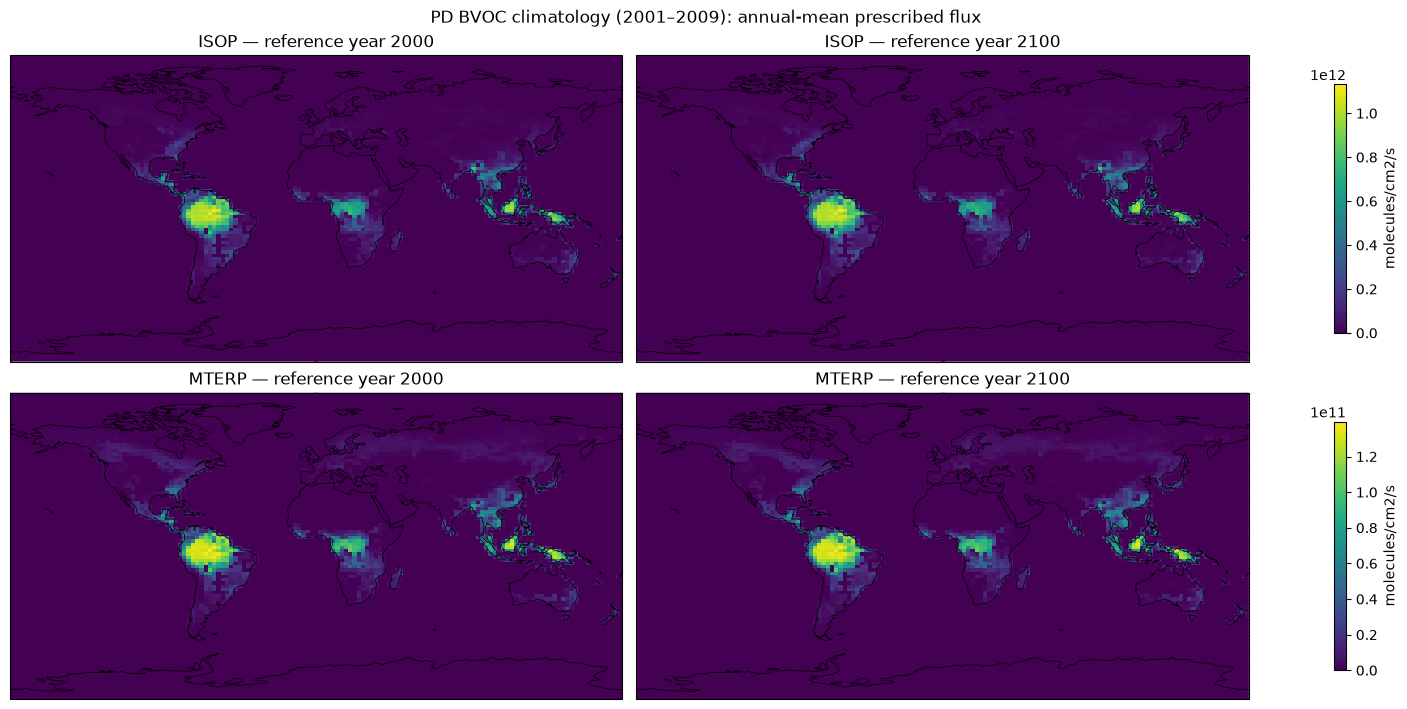

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7), subplot_kw={"projection": ccrs.PlateCarree()}, constrained_layout=True)
for row, (sp, var) in enumerate(SPECIES.items()):
    if units[sp, 2000] != units[sp, 2100]:
        raise ValueError(f"Different units in the two {var} files")
    low = min(float(means[sp, year].min()) for year in YEARS)
    high = max(float(means[sp, year].max()) for year in YEARS)
    vmin, vmax = min(0, low), max(high, 0)
    if vmin == vmax:
        vmax = vmin + 1
    for col, year in enumerate(YEARS):
        ax, field = axes[row, col], means[sp, year]
        values, lon = add_cyclic_point(field.values, coord=field.lon.values)
        mesh = ax.pcolormesh(lon, field.lat, values, transform=ccrs.PlateCarree(), cmap="viridis", vmin=vmin, vmax=vmax, shading="auto")
        ax.set_global()
        ax.coastlines(linewidth=0.5)
        ax.set_title(f"{var} — reference year {year}")
    fig.colorbar(mesh, ax=axes[row, :].tolist(), shrink=0.8, label=units[sp, 2000])
fig.suptitle("PD BVOC climatology (2001–2009): annual-mean prescribed flux")
plt.show()
# Optional: fig.savefig(DATA_DIR / "bvoc_annual_mean_maps.png", dpi=200, bbox_inches="tight")


In [5]:
import calendar

daily_series, seasonal_maps = {}, {}
SEASONS = {"DJF": (12, 1, 2), "MAM": (3, 4, 5),
           "JJA": (6, 7, 8), "SON": (9, 10, 11)}

for sp, var in SPECIES.items():
    for year in YEARS:
        suffix = "" if year == 2000 else "_on_yr2100"
        path = DATA_DIR / f"{PREFIX}{suffix}_{sp}.nc"
        print(f"Reading: {path.name}", flush=True)

        with xr.open_dataset(path, decode_times=False) as ds:
            # Use date rather than decoded time; works with noleap calendars.
            dates = ds["date"].values.astype(int)
            months = (dates // 100) % 100
            weights = np.cos(np.deg2rad(ds.lat))
            series, sums, counts = [], {}, {}

            # Process about one week at a time, without loading the whole file.
            for start in range(0, len(dates), 48 * 7):
                stop = min(start + 48 * 7, len(dates))
                flux = ds[var].isel(time=slice(start, stop)).load()
                series.append(flux.weighted(weights).mean(("lat", "lon")).values)

                for season, selected_months in SEASONS.items():
                    indices = np.flatnonzero(np.isin(months[start:stop], selected_months))
                    if len(indices):
                        selected = flux.isel(time=indices)
                        subtotal = selected.sum("time", skipna=False)
                        sums[season] = sums.get(season, 0) + subtotal
                        counts[season] = counts.get(season, 0) + len(indices)

            global_mean = xr.DataArray(np.concatenate(series), dims="sample",
                                       coords={"date": ("sample", dates)})
            daily_series[sp, year] = global_mean.groupby("date").mean()
            seasonal_maps[sp, year] = {s: sums[s] / counts[s] for s in SEASONS}

Reading: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_SFISOP.nc
Reading: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_on_yr2100_SFISOP.nc
Reading: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_SFMTERP.nc
Reading: ems_NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20260925_2001-2009_on_yr2100_SFMTERP.nc


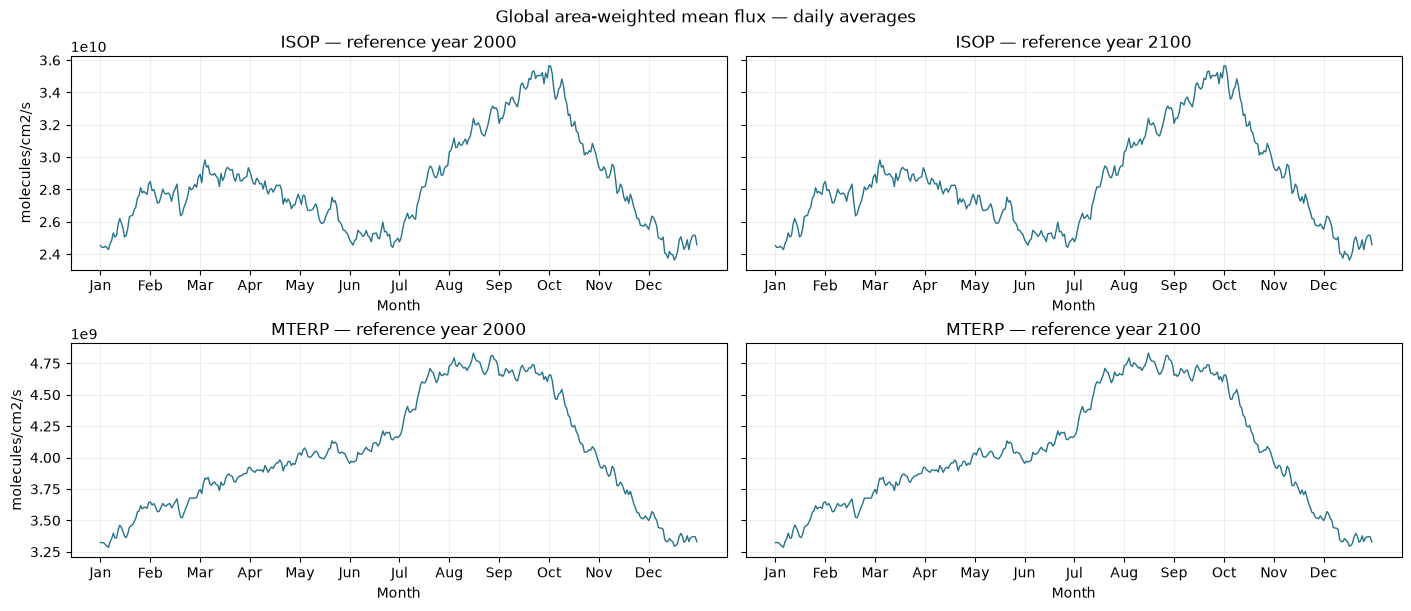

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(14, 6), sharey="row", constrained_layout=True)

for row, (sp, var) in enumerate(SPECIES.items()):
    for col, year in enumerate(YEARS):
        daily = daily_series[sp, year]
        dates = daily.date.values.astype(int)
        months, days = (dates // 100) % 100, dates % 100

        # Climatological month axis, independent of reference year.
        month_lengths = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])
        x = months + (days - 1) / month_lengths[months - 1]

        # An endpoint on 1 January of the following year belongs at the right edge.
        x = x + 12 * (dates // 10000 - year)
        ax = axes[row, col]
        ax.plot(x, daily.values, color="#25738A", linewidth=1)
        ax.set(title=f"{var} — reference year {year}", xlabel="Month",
               xticks=np.arange(1, 13), xticklabels=list(calendar.month_abbr)[1:])
        ax.grid(alpha=0.2)
        if col == 0:
            ax.set_ylabel(units[sp, year])

fig.suptitle("Global area-weighted mean flux — daily averages")
plt.show()

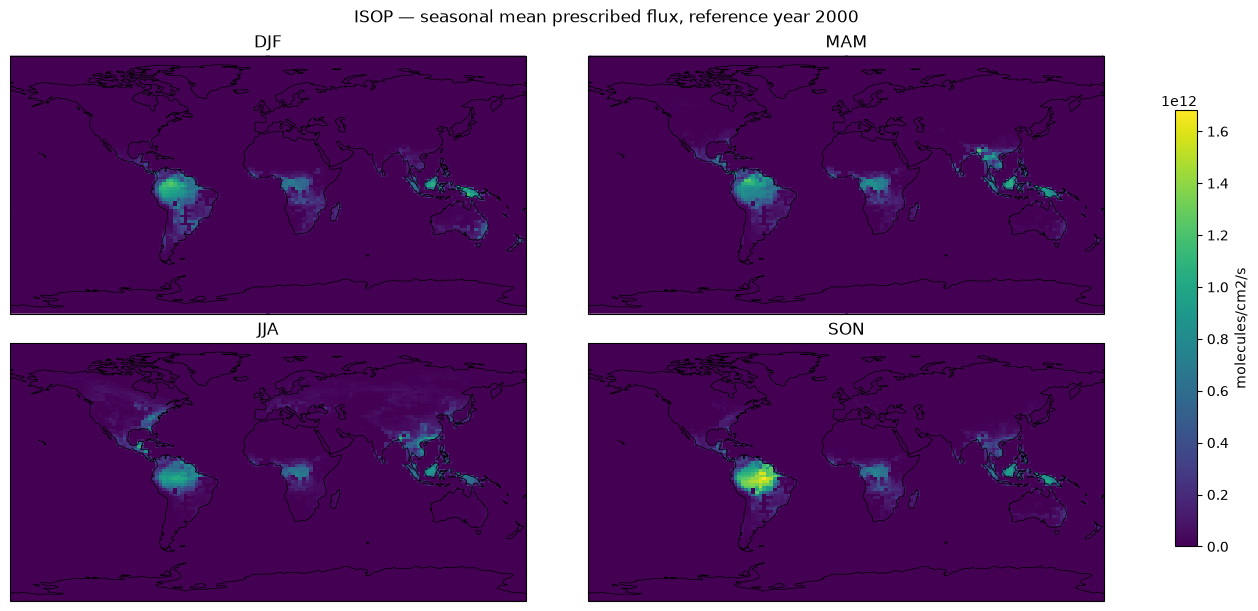

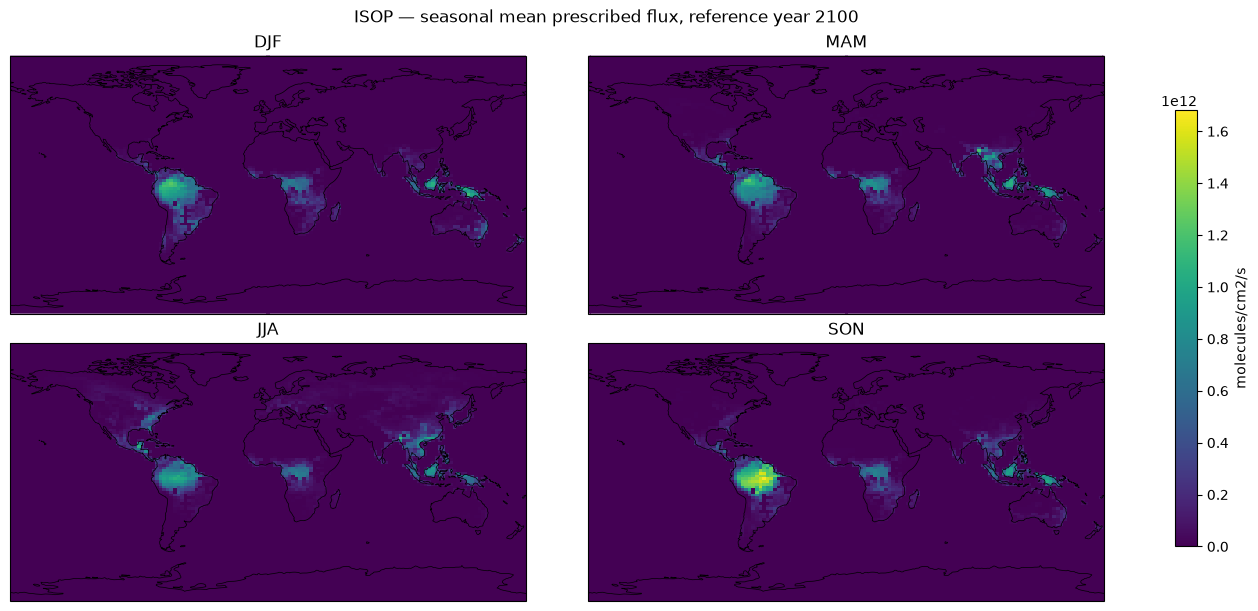

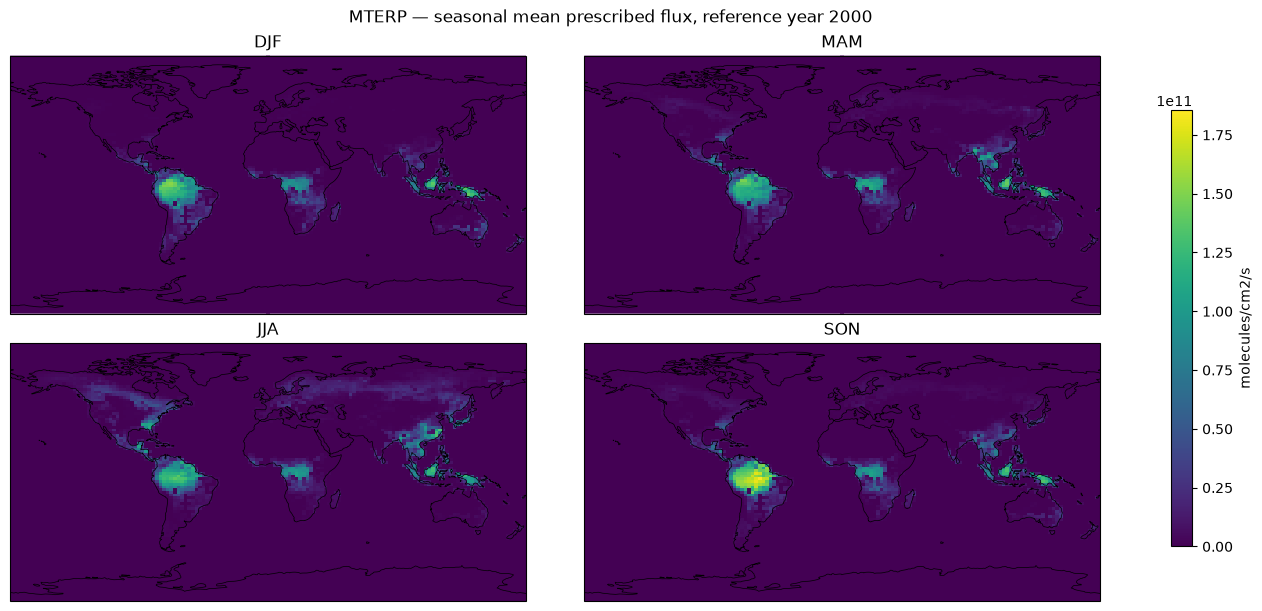

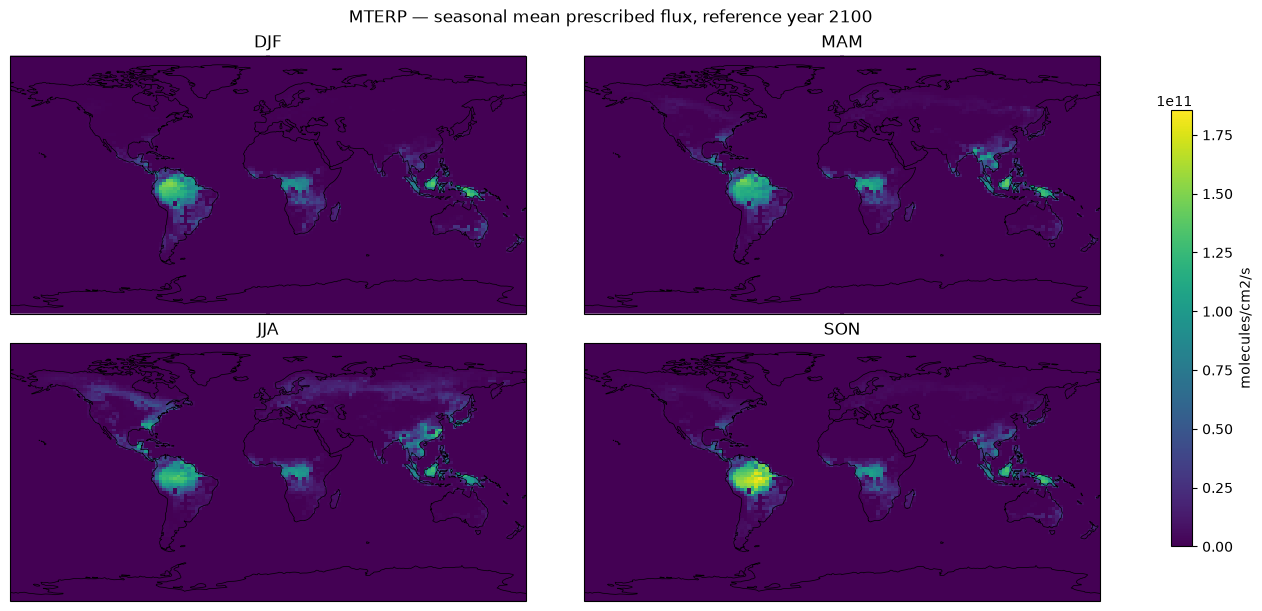

In [7]:
# One figure per file; common scale across both years and all seasons per species.
for sp, var in SPECIES.items():
    fields = [seasonal_maps[sp, year][s] for year in YEARS for s in SEASONS]
    vmin = min(0, min(float(field.min()) for field in fields))
    vmax = max(float(field.max()) for field in fields)
    if vmax <= vmin:
        vmax = vmin + 1

    for year in YEARS:
        fig, axes = plt.subplots(2, 2, figsize=(13, 6),
                                 subplot_kw={"projection": ccrs.PlateCarree()},
                                 constrained_layout=True)

        for ax, season in zip(axes.flat, SEASONS):
            field = seasonal_maps[sp, year][season]
            values, lon = add_cyclic_point(field.values, coord=field.lon.values)
            mesh = ax.pcolormesh(lon, field.lat, values, transform=ccrs.PlateCarree(),
                                 cmap="viridis", vmin=vmin, vmax=vmax, shading="auto")
            ax.set_global()
            ax.coastlines(linewidth=0.5)
            ax.set_title(season)

        fig.colorbar(mesh, ax=axes.ravel().tolist(), shrink=0.8, label=units[sp, year])
        fig.suptitle(f"{var} — seasonal mean prescribed flux, reference year {year}")
        plt.show()

## Arctic regions
### Discrete colorbar

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

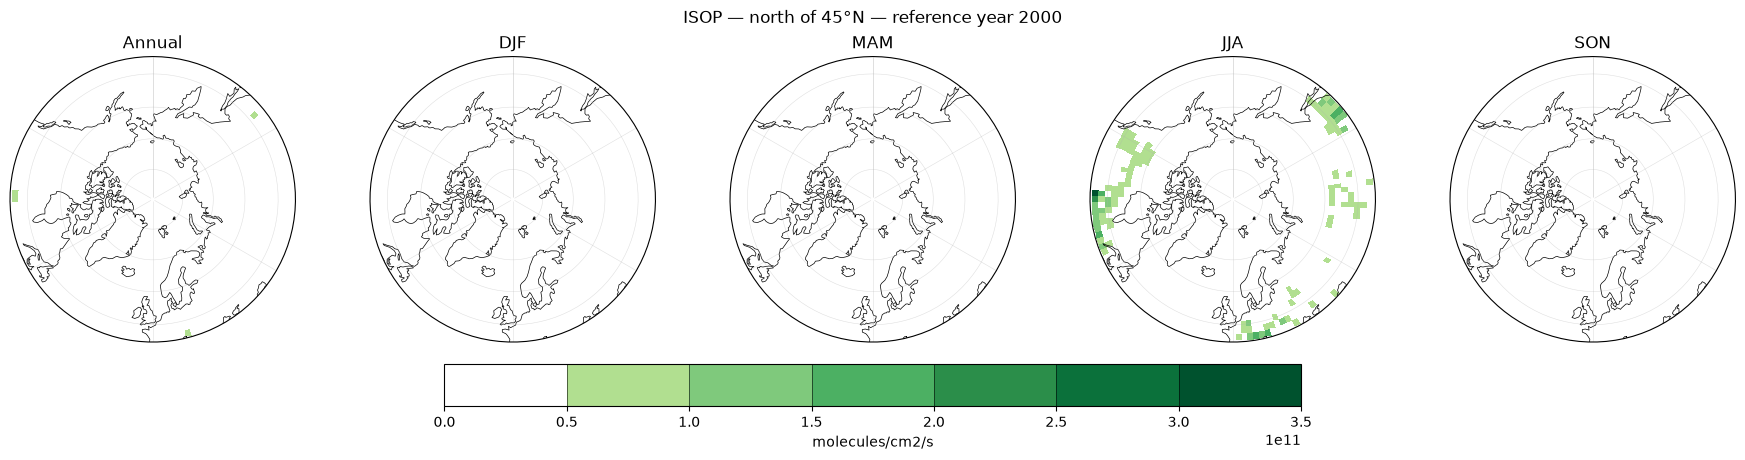

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

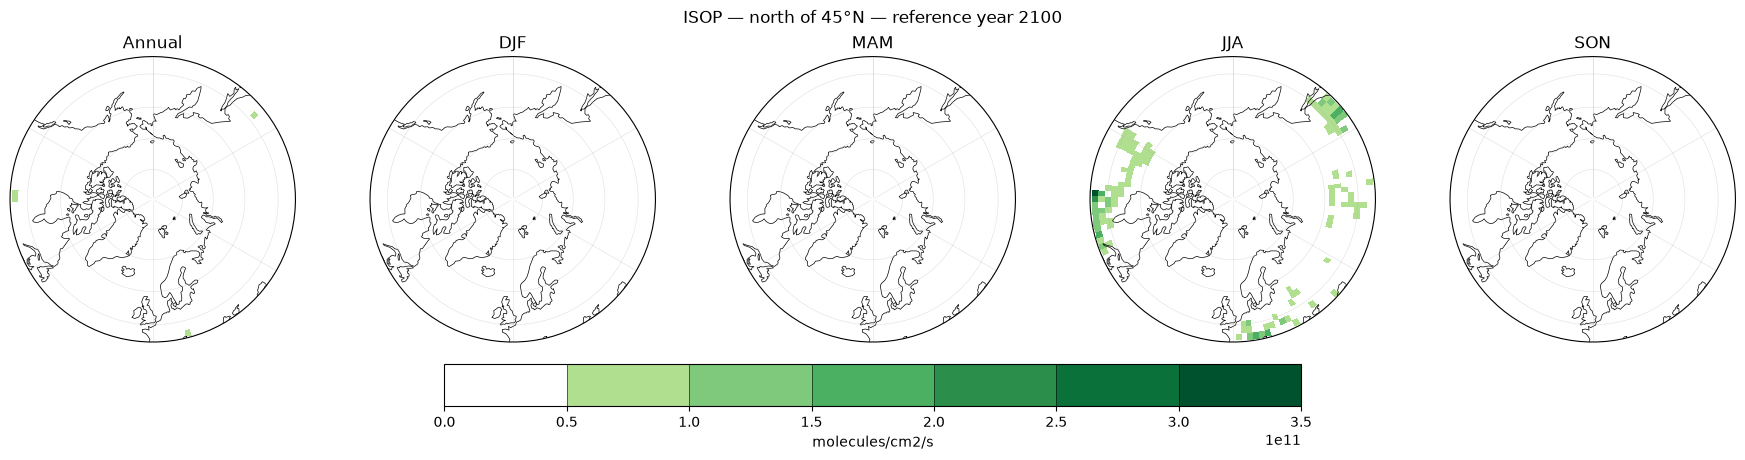

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

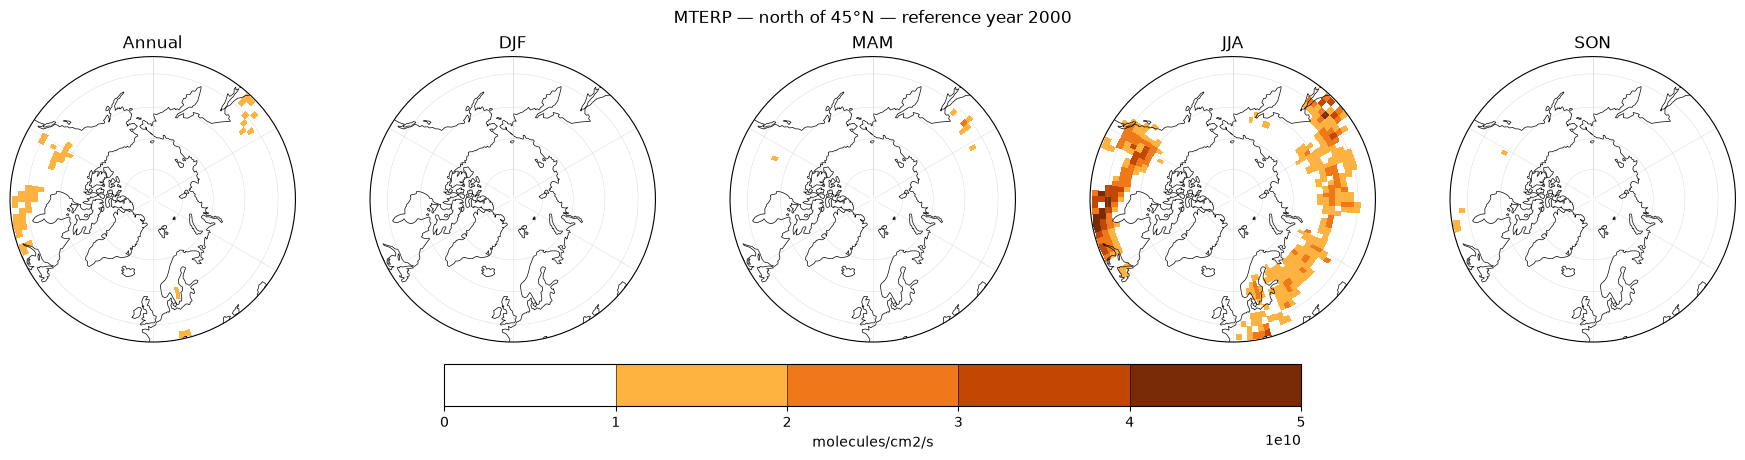

/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must be fully transparent.
  return func(self, *args, **kwargs)
/cluster/home/adelez/nird/.conda/envs/lcc-env/lib/python3.12/site-packages/cartopy/mpl/geoaxes.py:291: UserWarning: The colormap's 'bad' has been set, but in order to wrap pcolormesh across the map it must

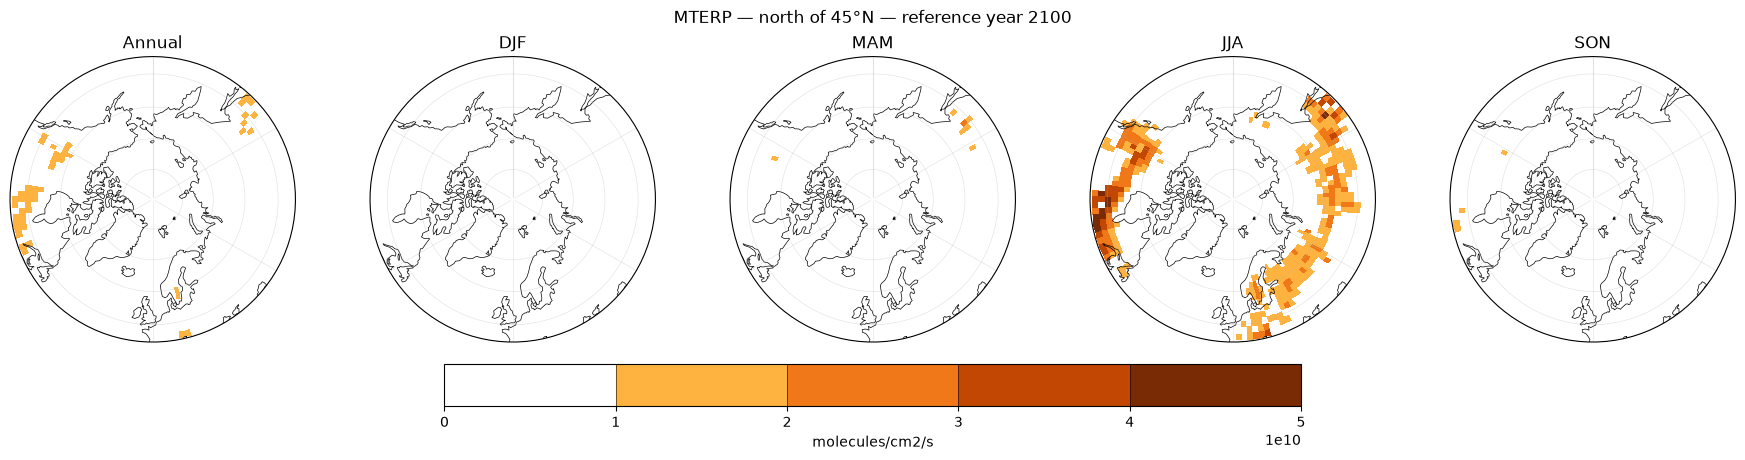

In [14]:
import matplotlib.path as mpath
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.ticker import MaxNLocator
YEARS = (2000,2100)

# Set explicit bin boundaries here if desired; None selects them automatically.
LEVELS = {"ISOP": None, "MTERP": None}
PALETTES = {"ISOP": "YlGn", "MTERP": "YlOrBr"}

theta = np.linspace(0, 2 * np.pi, 100)
circle = mpath.Path(np.column_stack([np.sin(theta), np.cos(theta)]) * 0.5 + 0.5)
projection = ccrs.NorthPolarStereo()

for sp, var in SPECIES.items():
    fields = [
        field.where(field.lat > 45, drop=True)
        for year in YEARS
        for field in [means[sp, year], *seasonal_maps[sp, year].values()]
    ]

    levels = LEVELS[var]
    if levels is None:
        vmax = max(float(field.max()) for field in fields)
        levels = MaxNLocator(nbins=7, steps=[1, 2, 2.5, 5, 10]).tick_values(0, max(vmax, 1e-30))
    levels = np.asarray(levels)

    # One colour per interval; the first interval is white.
    colors = plt.get_cmap(PALETTES[var])(np.linspace(0.25, 0.95, len(levels) - 1))
    colors[0] = [1, 1, 1, 1]
    cmap = ListedColormap(colors)
    cmap.set_bad("#dddddd")  # Missing data stays distinguishable from zero.
    norm = BoundaryNorm(levels, cmap.N)
    extend = "max" if max(float(field.max()) for field in fields) > levels[-1] else "neither"

    for year in YEARS:
        panels = {"Annual": means[sp, year], **seasonal_maps[sp, year]}
        fig, axes = plt.subplots(1, 5, figsize=(18, 4.5),
                                 subplot_kw={"projection": projection},
                                 constrained_layout=True)

        for ax, (label, field) in zip(axes, panels.items()):
            field = field.where(field.lat > 45, drop=True).transpose("lat", "lon")
            values, lon = add_cyclic_point(field.values, coord=field.lon.values)

            mesh = ax.pcolormesh(lon, field.lat, np.ma.masked_invalid(values),
                                 transform=ccrs.PlateCarree(), cmap=cmap, norm=norm,
                                 shading="auto")
            ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
            ax.set_boundary(circle, transform=ax.transAxes)
            ax.coastlines(linewidth=0.5)
            ax.gridlines(linewidth=0.4, alpha=0.4)
            ax.set_title(label)

        fig.colorbar(mesh, ax=axes.tolist(), orientation="horizontal",
                     boundaries=levels, ticks=levels, spacing="uniform",
                     drawedges=True, extend=extend, shrink=0.55, pad=0.05,
                     label=units[sp, year])
        fig.suptitle(f"{var} — north of 45°N — reference year {year}")
        plt.show()

### Continuous colorbar

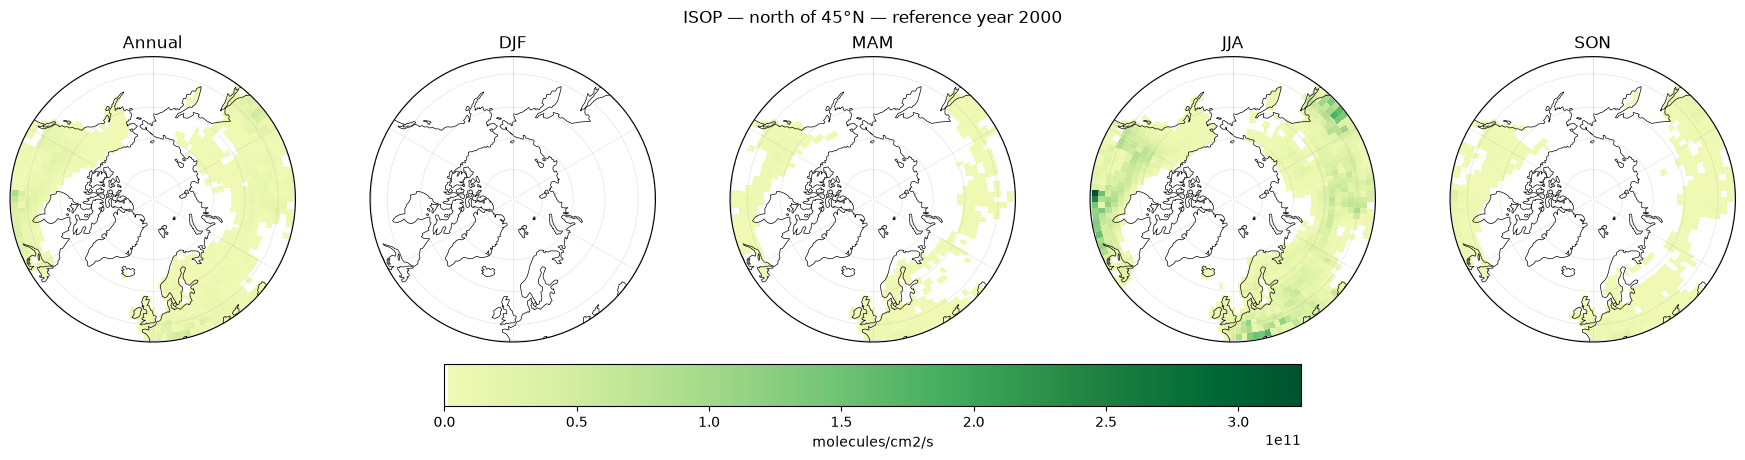

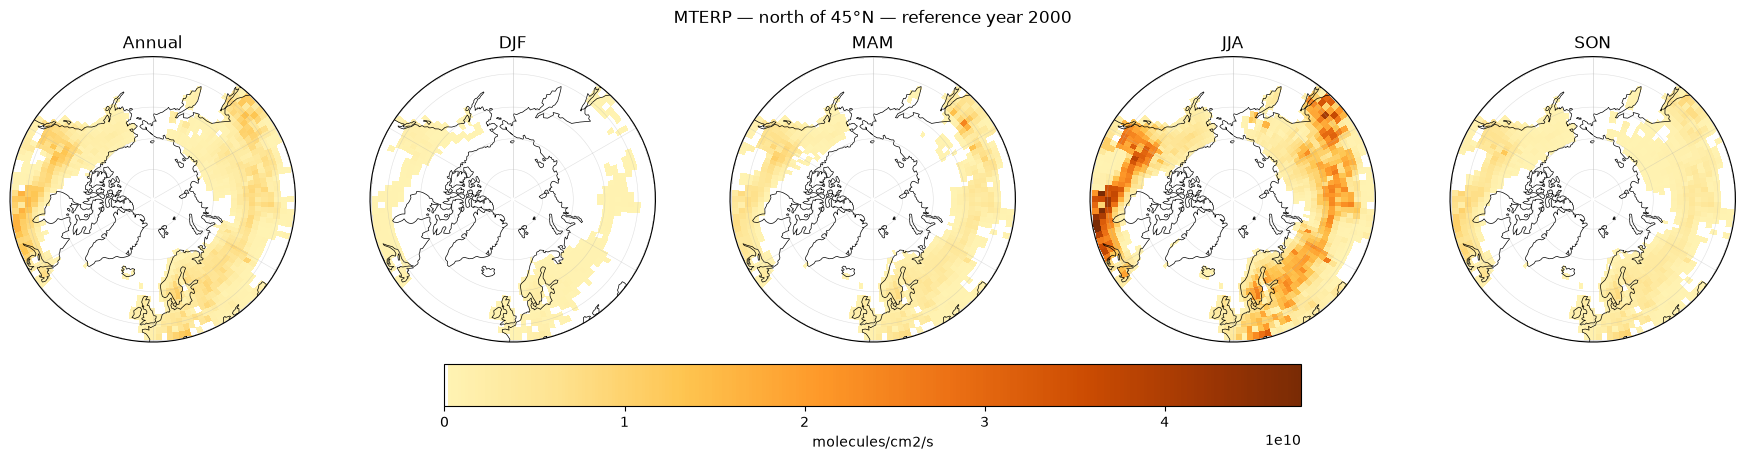

In [15]:
import matplotlib.path as mpath
from matplotlib.colors import LinearSegmentedColormap, Normalize

PALETTES = {"ISOP": "YlGn", "MTERP": "YlOrBr"}
VMAX = {"ISOP": None, "MTERP": None}  # Optional fixed upper limits.

theta = np.linspace(0, 2 * np.pi, 100)
circle = mpath.Path(np.column_stack([np.sin(theta), np.cos(theta)]) * 0.5 + 0.5)
projection = ccrs.NorthPolarStereo()
year = 2000

for sp, var in SPECIES.items():
    panels = {"Annual": means[sp, year], **seasonal_maps[sp, year]}
    panels = {label: field.where(field.lat > 45, drop=True).transpose("lat", "lon")
              for label, field in panels.items()}

    vmax = VMAX[var]
    if vmax is None:
        vmax = max(float(field.max()) for field in panels.values())
    vmax = max(vmax, 1e-30)

    # Continuous gradient from white to the species-specific colour.
    colors = plt.get_cmap(PALETTES[var])(np.linspace(0.15, 0.95, 256))
    colors[0] = [1, 1, 1, 1]
    cmap = LinearSegmentedColormap.from_list(f"{var}_white", colors)
    cmap.set_bad((0, 0, 0, 0))  # Transparent, as required by Cartopy.
    norm = Normalize(vmin=0, vmax=vmax)
    extend = "max" if any(float(f.max()) > vmax for f in panels.values()) else "neither"

    fig, axes = plt.subplots(1, 5, figsize=(18, 4.5),
                             subplot_kw={"projection": projection},
                             constrained_layout=True)

    for ax, (label, field) in zip(axes, panels.items()):
        values, lon = add_cyclic_point(field.values, coord=field.lon.values)
        ax.set_facecolor("#dddddd")

        mesh = ax.pcolormesh(lon, field.lat, np.ma.masked_invalid(values),
                             transform=ccrs.PlateCarree(), cmap=cmap, norm=norm,
                             shading="auto")
        ax.set_extent([-180, 180, 45, 90], crs=ccrs.PlateCarree())
        ax.set_boundary(circle, transform=ax.transAxes)
        ax.coastlines(linewidth=0.5)
        ax.gridlines(linewidth=0.4, alpha=0.4)
        ax.set_title(label)

    fig.colorbar(mesh, ax=axes.tolist(), orientation="horizontal",
                 extend=extend, shrink=0.55, pad=0.05, label=units[sp, year])
    fig.suptitle(f"{var} — north of 45°N — reference year {year}")
    plt.show()

In [21]:
# 1. Load the modified-cell mask.
MASK_FILE = Path("/cluster/home/adelez/BOREAL-FOREST-EXPANSION/diagnostics/check-simulation-equilibrium/lcc-modified-cells/modified_cells.nc")  # Set your actual file.
MASK_VAR = "modified"                    # Set your actual variable.

with xr.open_dataset(MASK_FILE) as ds:
    #display(ds)
    mask = ds[MASK_VAR].squeeze(drop=True).load()

# Accept only a Boolean or 0/1 mask; missing cells are excluded.
if not np.isin(mask.values[np.isfinite(mask.values)], [0, 1]).all():
    raise ValueError("Expected a Boolean or 0/1 modified-cell mask.")
mask = mask.fillna(0).astype(bool)
# mask = mask & (mask.lat > 45)

# 2. Read in small chunks and calculate daily means.
modified_daily = {}
year = 2000

for sp, var in SPECIES.items():
    path = DATA_DIR / f"{PREFIX}_{sp}.nc"
    print(f"Reading modified cells: {var}", flush=True)

    with xr.open_dataset(path, decode_times=False) as ds:
        # Require matching coordinates rather than silently misaligning cells.
        aligned_mask = mask.assign_coords(lon=mask.lon % 360).sortby("lat").sortby("lon")

        for coord in ("lat", "lon"):
            target = ds[coord].values
            target_normalized = target % 360 if coord == "lon" else target
            order = np.argsort(target_normalized)
            source = aligned_mask[coord].values
        
            if source.shape != target.shape:
                raise ValueError(f"{coord}: different grid sizes: mask={source.size}, emissions={target.size}")
        
            difference = np.max(np.abs(source - target_normalized[order]))
            if difference > 1e-5:
                raise ValueError(f"{coord}: grids differ by up to {difference:.6g}°; inspect before remapping.")
        
            # Restore the emissions file's ordering, then copy its coordinate labels.
            aligned_mask = aligned_mask.isel({coord: np.argsort(order)})
            aligned_mask = aligned_mask.assign_coords({coord: ds[coord]})
        #_, aligned_mask = xr.align(ds[var].isel(time=0, drop=True), mask, join="exact")
        weights = np.cos(np.deg2rad(ds.lat)).where(aligned_mask, 0)
        if float(weights.sum()) <= 0:
            raise ValueError("No modified cells with positive area weights.")

        dates = ds.date.values.astype(int)
        values = []
        for start in range(0, len(dates), 48 * 7):
            flux = ds[var].isel(time=slice(start, start + 48 * 7)).load()
            values.append(flux.weighted(weights).mean(("lat", "lon")).values)

        series = xr.DataArray(np.concatenate(values), dims="sample",
                              coords={"date": ("sample", dates)})
        modified_daily[sp] = series.groupby("date").mean()

Reading modified cells: ISOP
Reading modified cells: MTERP


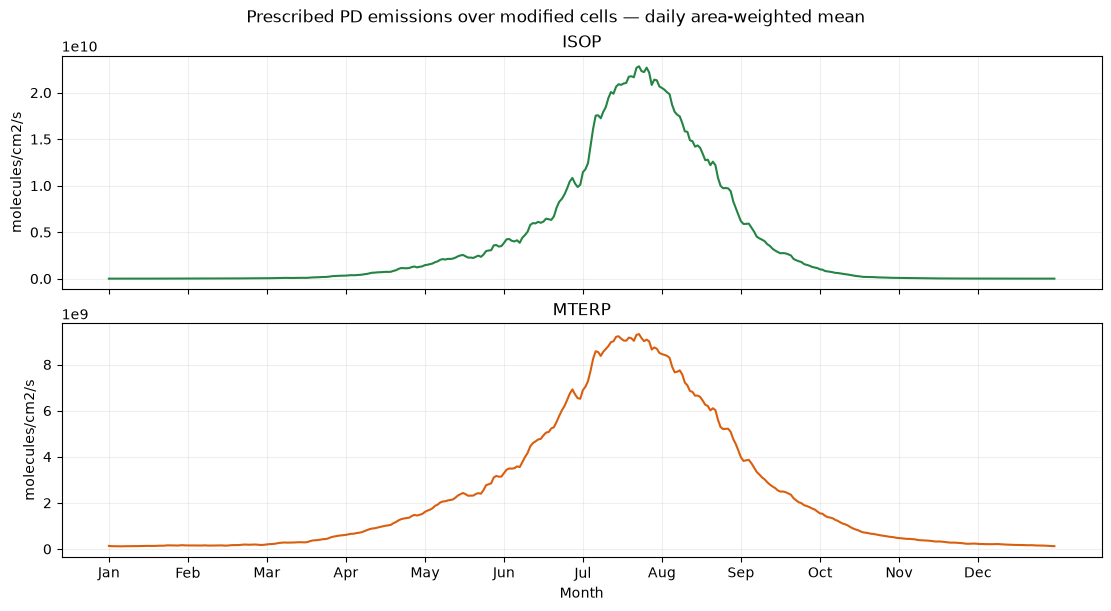

In [22]:
# 3. Plot using the same month axis as your global time series.
import calendar

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True, constrained_layout=True)
month_lengths = np.array([31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31])

for ax, (sp, var) in zip(axes, SPECIES.items()):
    daily = modified_daily[sp]
    dates = daily.date.values.astype(int)
    months, days = (dates // 100) % 100, dates % 100
    x = months + (days - 1) / month_lengths[months - 1]
    x += 12 * (dates // 10000 - year)

    ax.plot(x, daily.values, color={"ISOP": "#238443", "MTERP": "#D95F0E"}[var])
    ax.set(title=var, ylabel=units[sp, year])
    ax.grid(alpha=0.2)

axes[-1].set(xticks=np.arange(1, 13), xticklabels=list(calendar.month_abbr)[1:],
             xlabel="Month")
fig.suptitle("Prescribed PD emissions over modified cells — daily area-weighted mean")
plt.show()